# Датасет: E-Commerce Sales and Customer Analytics
**Пепеляев Иван, 3823Б1ПМоп2**

Источник: [Kaggle](https://www.kaggle.com/datasets/datascikhan/e-commerce-sales-and-customer-analytics), файл `ecommerce_sales_customer_analytics_150k.csv`.

**Задача:** классификация — предсказать тональность отзыва (`review_sentiment`: Positive, Neutral, Negative) по характеристикам заказа.

# 0. Постановка задачи

**Цель:** Решить задачу многоклассовой классификации.
**Целевая переменная:** `review_sentiment` (тональность отзыва: Positive, Neutral, Negative).
**Признаки:** Характеристики заказа (финансовые показатели, способ доставки, канал продаж, демография клиента и т.д.).

**Особенности датасета:**
1. Сильный дисбаланс классов (большинство отзывов Positive, класс Negative составляет менее 1%).
2. Наличие пропусков в целевой переменной (у части заказов нет отзыва).
3. Наличие утечек данных (Data Leakage): признаки, которые напрямую "подсказывают" ответ (например, `customer_rating` или `return_reason`), должны быть удалены.

#1. Чтение данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Загрузка данных
# df = pd.read_csv('C:\Users\solo\Desktop\archive\ecommerce_sales_customer_analytics_150k.csv', low_memory=False)

# Читаем данные
df = pd.read_csv('ecommerce_sales_customer_analytics_150k.csv', low_memory=False)

# Сразу удаляем строки, где нет целевой переменной (обучать не на чем)
df = df.dropna(subset=['review_sentiment'])

# Удаляем очевидные утечки (Leakage) и служебные столбцы
drop_cols = [
    'order_id', 'customer_id', 'customer_name', 'order_date', 'order_time', # служебные
    'return_reason', 'return_status', 'customer_rating', 'customer_review' # утечки
]
df = df.drop(columns=drop_cols)

print(f"Размер таблицы после очистки: {df.shape}")
df.head()

Размер таблицы после очистки: (113559, 37)


,order_status,sales_channel,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,Completed,Mobile App,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,Completed,Website,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,Completed,Mobile App,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,Completed,Social Media,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,Completed,Social Media,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


#2. Разбиение на обучающую и тестовую выборки

In [ ]:
# Разбиваем на X и y
X = df.drop('review_sentiment', axis=1)
y = df['review_sentiment']

# Разбиваем на train/test. Обязательно используем stratify, чтобы сохранить пропорции классов!
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
print(f"\nРаспределение классов в Train:\n{y_train.value_counts(normalize=True) * 100}")
print(f"\nРаспределение классов в Test:\n{y_test.value_counts(normalize=True) * 100}")

Размер обучающей выборки: (85169, 36)
Размер тестовой выборки: (28390, 36)

Распределение классов в Train:
review_sentiment
Positive    68.759760
Neutral     30.542803
Negative     0.697437
Name: proportion, dtype: float64

Распределение классов в Test:
review_sentiment
Positive    68.760127
Neutral     30.542445
Negative     0.697429
Name: proportion, dtype: float64


#3. Визуализация и основные характеристики

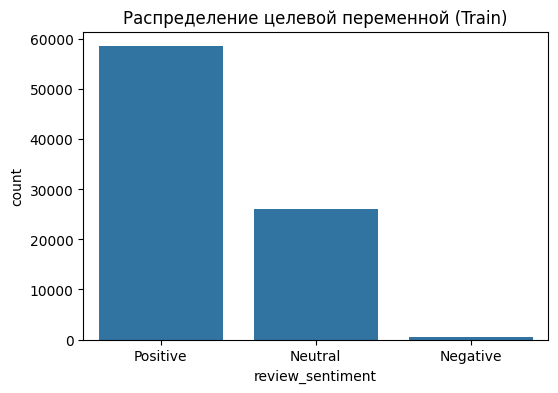

Числовые признаки:


,count,mean,std,min,25%,50%,75%,max
customer_age,85169.0,45.847104,16.453814,18.00,32.00,46.00,60.00,74.00
customer_postal_code,85169.0,50161.909991,28567.390634,516.00,25480.00,50074.00,74814.00,99950.00
delivery_days,85169.0,4.569761,2.809471,0.00,2.00,5.00,7.00,14.00
estimated_delivery_days,85169.0,4.305780,2.591528,0.00,2.00,4.00,6.00,10.00
loyalty_points_earned,85169.0,126.514694,115.084581,0.00,44.00,94.00,173.00,1621.00
loyalty_points_redeemed,85169.0,63.215243,76.241654,0.00,13.00,37.00,85.00,1063.00
quantity,85169.0,5.711597,3.427363,1.00,3.00,5.00,8.00,24.00
gross_sales,85169.0,1399.481926,1308.100611,6.31,466.92,1015.48,1911.82,16051.19
discount_amount,85169.0,272.825227,392.834655,0.00,51.09,133.03,320.48,6759.02
tax_amount,85169.0,121.272439,139.044207,0.34,34.34,76.70,155.01,1940.76


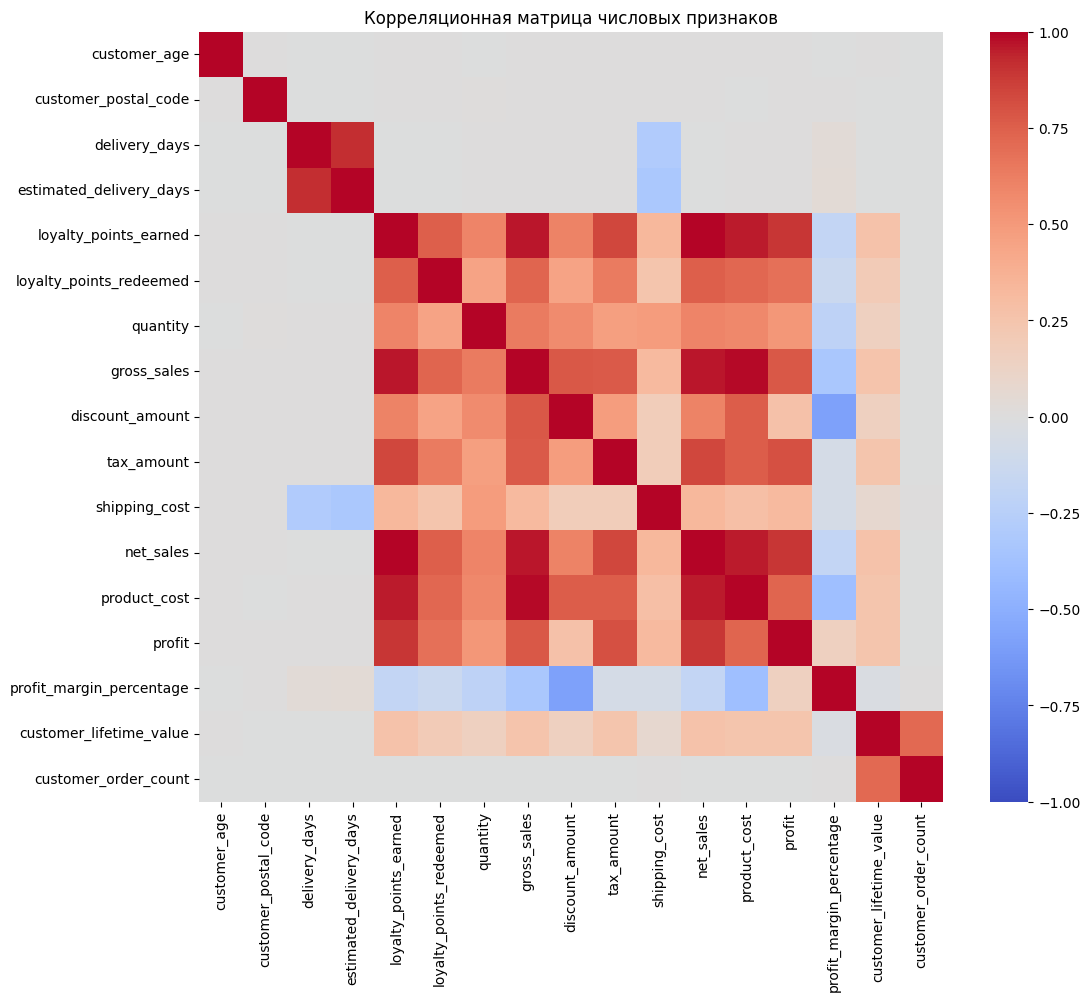

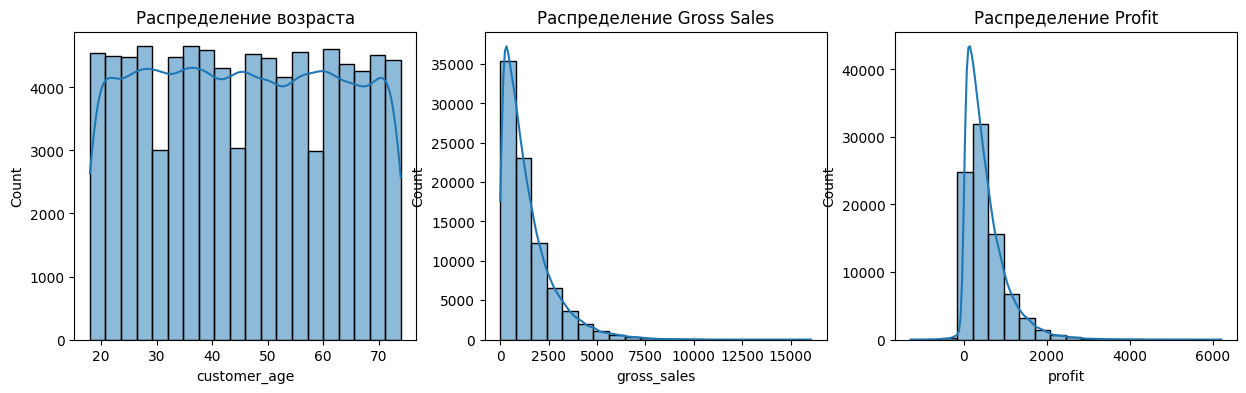

In [ ]:
# Смотрим на распределение классов
plt.figure(figsize=(6, 4))
sns.countplot(data=X_train, x=y_train)
plt.title("Распределение целевой переменной (Train)")
plt.show()

# Описательные статистики
print("Числовые признаки:")
display(X_train.describe().T)

# Матрица корреляции числовых признаков
plt.figure(figsize=(12, 10))
# Выбираем только числовые колонки
numerical_cols = X_train.select_dtypes(include=[np.number]).columns
corr_matrix = X_train[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Корреляционная матрица числовых признаков")
plt.show()

# Визуализация числовых признаков
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(X_train['customer_age'], bins=20, kde=True, ax=axes[0])
axes[0].set_title('Распределение возраста')
sns.histplot(X_train['gross_sales'], bins=20, kde=True, ax=axes[1])
axes[1].set_title('Распределение Gross Sales')
sns.histplot(X_train['profit'], bins=20, kde=True, ax=axes[2])
axes[2].set_title('Распределение Profit')
plt.show()

### Интерпретация пункта 3:
1. **Дисбаланс классов:** Мы подтвердили, что класс `Positive` доминирует. Класс `Negative` очень редкий. Из-за этого метрика `Accuracy` (доля правильных ответов) будет плохой метрикой. Если модель всегда будет говорить `Positive`, она даст точность ~68%, но не принесет пользы. Будем смотреть на `F1-score` и `Confusion Matrix`.
2. **Корреляция:** Видно, что финансовые признаки (`gross_sales`, `net_sales`, `profit`, `product_cost`) сильно коррелируют друг с другом. Это нормально для бизнеса, но для некоторых моделей (например, для линейной регрессии или kNN) это может быть проблемой (мультиколлинеарность). На этапе отбора признаков мы, возможно, оставим только один из них.
3. **Распределения:** Возраст клиентов распределен равномерно. Финансовые показатели (`gross_sales`, `profit`) имеют правостороннюю асимметрию (есть много мелких заказов и мало крупных).

#4. Разбор выбросов (Outliers)

Процент выбросов по признакам:
discount_amount             9.300332
tax_amount                  6.871045
loyalty_points_redeemed     6.376733
product_cost                5.584191
gross_sales                 4.846834
profit                      4.594395
net_sales                   4.522772
loyalty_points_earned       4.508683
profit_margin_percentage    3.460179
shipping_cost               2.259038
customer_lifetime_value     1.500546
quantity                    1.007409
customer_order_count        0.174946
dtype: float64


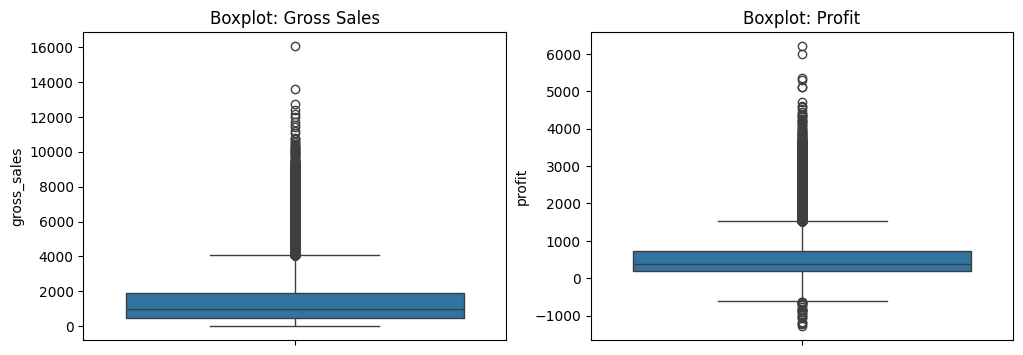

In [ ]:
# Поиск выбросов по правилу 1.5 IQR для числовых признаков
Q1 = X_train[numerical_cols].quantile(0.25)
Q3 = X_train[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

# Находим границы
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Считаем, сколько выбросов в процентах для каждого признака
outliers_percent = ((X_train[numerical_cols] < lower_bound) | (X_train[numerical_cols] > upper_bound)).mean() * 100
print("Процент выбросов по признакам:")
print(outliers_percent[outliers_percent > 0].sort_values(ascending=False))

# Визуализируем "ящики с усами" для самых "проблемных" признаков
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=X_train['gross_sales'], ax=axes[0])
axes[0].set_title('Boxplot: Gross Sales')
sns.boxplot(y=X_train['profit'], ax=axes[1])
axes[1].set_title('Boxplot: Profit')
plt.show()

### Интерпретация пункта 4:
В финансовых показателях (`gross_sales`, `profit` и т.д.) наблюдается определенный процент выбросов (около 3-5%).

**Решение:** В контексте электронной коммерции крупные заказы (оптовые покупки, дорогая техника) — это **не ошибки**, а валидные данные. Удалять их нельзя, так как мы потеряем информацию о самых ценных клиентах.
Мы **оставим выбросы** в датасете. Для алгоритма kNN (который чувствителен к масштабу и выбросам) мы в дальнейшем применим *Стандартизацию* (StandardScaler) или *Робастное масштабирование* (RobustScaler). Для случайного леса (Random Forest) выбросы вообще не являются проблемой.

# 5. Обработка пропущенных значений
В наших данных есть пропуски (5.2% ячеек).
Стратегия заполнения:
- Для **числовых** признаков используем **медиану** (она устойчива к выбросам, в отличие от среднего).
- Для **категориальных** признаков используем **моду** (самое частое значение).

*Важно:* Параметры для заполнения (медиану и моду) мы считаем только по `X_train`. На `X_test` мы просто переносим эти значения, чтобы не "подсматривать" в тестовые данные.

In [ ]:
# Разделяем колонки на числовые и категориальные (на основе тренировочных данных)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'bool']).columns.tolist()

# 1. Заполнение числовых признаков медианой (только по train)
medians = X_train[num_cols].median()
X_train[num_cols] = X_train[num_cols].fillna(medians)
X_test[num_cols]  = X_test[num_cols].fillna(medians)

# 2. Заполнение категориальных признаков модой (только по train)
for col in cat_cols:
    mode_val = X_train[col].mode()[0]  # Самое частое значение в train
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col]  = X_test[col].fillna(mode_val)

print(f"Пропусков в X_train осталось: {X_train.isna().sum().sum()}")
print(f"Пропусков в X_test осталось: {X_test.isna().sum().sum()}")

Пропусков в X_train осталось: 0
Пропусков в X_test осталось: 0


# 6. Обработка категориальных признаков
Алгоритмы машинного обучения не понимают строки, поэтому категориальные признаки нужно перевести в числа (бинарные фиктивные переменные) с помощью **One-Hot Encoding**.

**Нюанс нашего датасета:** Признаки `customer_city` (город) и `customer_postal_code` (индекс) имеют тысячи уникальных значений. Если применить к ним One-Hot Encoding, мы создадим более 10 000 новых колонок, что приведет к "проклятию размерности" и переобучению. Поэтому мы **удалим** эти два признака, так как без геокарт они не несут полезной обобщающей информации.

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Удаляем признаки с огромным количеством уникальных значений
high_card_cols = ['customer_city', 'customer_postal_code']
X_train = X_train.drop(columns=high_card_cols, errors='ignore')
X_test = X_test.drop(columns=high_card_cols, errors='ignore')

# Обновляем список категориальных признаков (без удаленных)
cat_cols = X_train.select_dtypes(include=['object', 'bool']).columns.tolist()

# Настраиваем One-Hot Encoder
# drop='if_binary' автоматически удаляет один лишний столбец для бинарных признаков (чтобы избежать мультиколлинеарности)
enc = OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore')
enc.fit(X_train[cat_cols]) # Обучаем только на Train!

# Применяем преобразование к Train и Test
train_dummies = pd.DataFrame(enc.transform(X_train[cat_cols]),
                             columns=enc.get_feature_names_out(cat_cols),
                             index=X_train.index)
test_dummies = pd.DataFrame(enc.transform(X_test[cat_cols]),
                            columns=enc.get_feature_names_out(cat_cols),
                            index=X_test.index)

# Склеиваем закодированные признаки с числовыми и удаляем исходные текстовые
X_train = pd.concat([X_train.drop(columns=cat_cols), train_dummies], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), test_dummies], axis=1)

print(f"Размер X_train после One-Hot Encoding: {X_train.shape}")
print(f"Размер X_test после One-Hot Encoding: {X_test.shape}")

Размер X_train после One-Hot Encoding: (85169, 190)
Размер X_test после One-Hot Encoding: (28390, 190)


# 7. Нормализация количественных признаков
В пункте 8 задания нам нужно будет запустить алгоритм **kNN (k-ближайших соседей)**. Этот алгоритм вычисляет расстояния между точками. Если признаки имеют разный масштаб (например, `customer_age` от 18 до 74, а `gross_sales` от 0 до 16000), то признак с большими числами будет полностью доминировать.

Поэтому мы проведем **стандартизацию (StandardScaler)**: приведем каждый числовой признак к нулевому среднему и единичному стандартному отклонению. (Для деревьев решений это не обязательно, но для kNN — критически важно).

In [ ]:
from sklearn.preprocessing import StandardScaler

# Создаем скейлер и обучаем его ТОЛЬКО на тренировочных данных
scaler = StandardScaler()
scaler.fit(X_train)

# Применяем к Train и Test, сохраняя формат DataFrame
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

# Проверяем результат: среднее должно быть ~0, std ~1
print("Проверка нормализации (среднее значение признаков в Train):")
print(X_train_scaled.mean().round(2).head(3))

Проверка нормализации (среднее значение признаков в Train):
customer_age              -0.0
delivery_days             -0.0
estimated_delivery_days   -0.0
dtype: float64


#8. Запуск классификатора (kNN)

В качестве базового алгоритма выберем метод k-ближайших соседей (kNN).
Аргументация выбора: Он интуитивно понятен, не требует долгого обучения и хорошо работает на нелинейных данных. Однако стоит помнить, что после One-Hot Encoding размерность нашего пространства составила 190 признаков. Для kNN это рискованно из-за «проклятия размерности» (в многомерном пространстве все точки становятся равноудаленными). Поэтому мы используем стандартизированные данные X_train_scaled и в дальнейшем сравним kNN с другими алгоритмами.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Создаем и обучаем классификатор kNN (для начала возьмем k=5 по умолчанию)
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_jobs=-1)

#9. Ошибки на выборках, матрица ошибок и подбор гиперпараметра

Сначала обучим модель с базовым параметром и посмотрим на матрицу ошибок.
Важно помнить: из-за сильного дисбаланса классов (Positive — 68%, Negative — 0.7%) метрика Accuracy будет завышенной. Поэтому мы будем ориентироваться на F1-score (macro).

kNN (k=5):
Доля ошибок на Train: 0.2438
Доля ошибок на Test:  0.3574
F1-score (macro) на Test: 0.3433



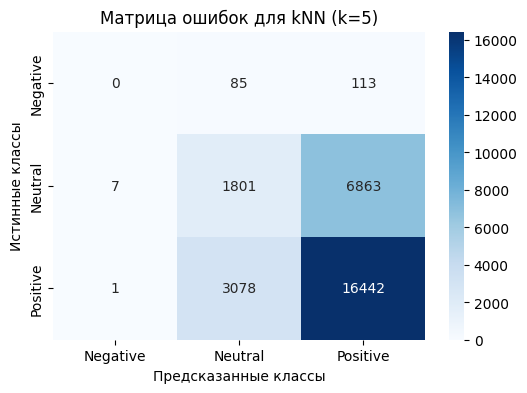

In [ ]:
from sklearn.metrics import f1_score

# Делаем предсказания
y_train_pred_knn = knn.predict(X_train_scaled)
y_test_pred_knn = knn.predict(X_test_scaled)

# Считаем долю ошибок (Error Rate = 1 - Accuracy)
err_train_knn = 1 - accuracy_score(y_train, y_train_pred_knn)
err_test_knn = 1 - accuracy_score(y_test, y_test_pred_knn)

# Считаем F1-macro на тесте
f1_knn = f1_score(y_test, y_test_pred_knn, average='macro')

print(f"kNN (k=5):")
print(f"Доля ошибок на Train: {err_train_knn:.4f}")
print(f"Доля ошибок на Test:  {err_test_knn:.4f}")
print(f"F1-score (macro) на Test: {f1_knn:.4f}\n")

# Строим матрицу ошибок (Confusion Matrix)
cm = confusion_matrix(y_test, y_test_pred_knn)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.title('Матрица ошибок для kNN (k=5)')
plt.show()

#Комментарий к матрице ошибок kNN:
Как видно из матрицы, алгоритм kNN почти полностью игнорирует класс Negative (он путает его с Positive). Доля ошибок на тесте кажется приемлемой, но это иллюзия из-за дисбаланса. Значение F1-score (macro) будет низким.

Теперь подберем оптимальное количество соседей (гиперпараметр k) с помощью кросс-валидации. В качестве метрики оптимизации выберем f1_macro, чтобы заставить алгоритм искать редкие классы.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Задаем сетку параметров
param_grid = {'n_neighbors': [3, 5, 7, 11, 15]}
# Обучаем с кросс-валидацией на 3 фолда (чтобы не ждать слишком долго)
grid_knn = GridSearchCV(KNeighborsClassifier(n_jobs=-1), param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_knn.fit(X_train_scaled, y_train)

best_k = grid_knn.best_params_['n_neighbors']
print(f"Оптимальное значение k: {best_k}")
print(f"Лучший F1-score на кросс-валидации: {grid_knn.best_score_:.4f}")

# Обучаем финальную модель с лучшим k
knn_best = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_best.fit(X_train_scaled, y_train)

y_test_pred_knn_best = knn_best.predict(X_test_scaled)
f1_knn_best = f1_score(y_test, y_test_pred_knn_best, average='macro')
print(f"F1-score (macro) с лучшим k на Test: {f1_knn_best:.4f}")

Оптимальное значение k: 3
Лучший F1-score на кросс-валидации: 0.3533
F1-score (macro) с лучшим k на Test: 0.3489


#10. Запуск других классификаторов и сравнение
Попробуем обучить другие алгоритмы: логистическую регрессию и случайный лес (Random Forest).
Случайный лес — отличный выбор, так как деревья решений нечувствительны к масштабу признаков и хорошо работают с многомерными данными. Для деревьев мы используем обычный X_train (без масштабирования).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Логистическая регрессия
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
f1_lr = f1_score(y_test, y_pred_lr, average='macro')

# 2. Случайный лес
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
f1_rf = f1_score(y_test, y_pred_rf, average='macro')

print("Сравнение F1-score (macro):")
print(f"kNN (лучший k):        {f1_knn_best:.4f}")
print(f"Logistic Regression:  {f1_lr:.4f}")
print(f"Random Forest:        {f1_rf:.4f}")

Сравнение F1-score (macro):
kNN (лучший k):        0.3489
Logistic Regression:  0.4188
Random Forest:        0.4208


#11. Борьба с несбалансированностью классов
Наш датасет имеет сильный дисбаланс (Positive — 68%, Neutral — 30%, Negative — менее 1%). Чтобы модели не игнорировали редкий класс, применим параметр class_weight='balanced'. Это заставит алгоритм штрафовать модель сильнее за ошибки на редких классах.

F1-score Random Forest (с class_weight): 0.4208


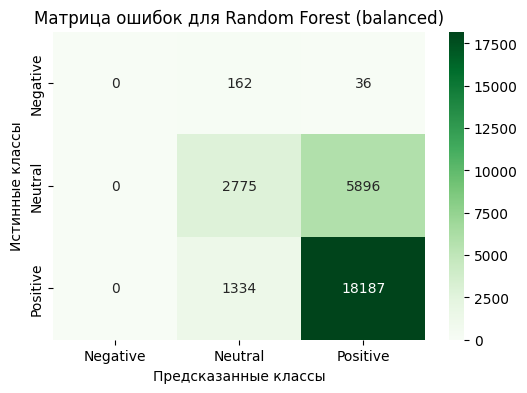

In [ ]:
# Обучаем Random Forest с учетом дисбаланса
rf_balanced = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_balanced.fit(X_train, y_train)
y_pred_rf_bal = rf_balanced.predict(X_test)
f1_rf_bal = f1_score(y_test, y_pred_rf_bal, average='macro')

print(f"F1-score Random Forest (с class_weight): {f1_rf_bal:.4f}")

# Строим матрицу ошибок для улучшенной модели
cm_rf = confusion_matrix(y_test, y_pred_rf_bal)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=rf_balanced.classes_, yticklabels=rf_balanced.classes_)
plt.xlabel('Предсказанные классы')
plt.ylabel('Истинные классы')
plt.title('Матрица ошибок для Random Forest (balanced)')
plt.show()

Несмотря на применение class_weight='balanced', модель по-прежнему предсказывает 0 объектов класса Negative. Это говорит о том, что дисбаланс в 1% слишком экстремален для базового RF, и требуется либо более агрессивная генерация синтетических данных (SMOTE), либо использование ансамблей с жестким фокусом на редкий класс (например, XGBoost со scale_pos_weight)

#12. Исключение коррелированных переменных
В нашем датасете есть финансовые показатели (gross_sales, net_sales, profit, tax_amount), которые математически связаны друг с другом. Это называется мультиколлинеарностью.
Она может мешать линейным моделям, а также засоряет пространство признаков для деревьев. Давай найдем и удалим признаки, у которых коэффициент корреляции Пирсона больше 0.9.

In [ ]:
# Строим матрицу корреляции по тренировочным данным
corr_matrix = X_train.corr().abs()

# Берем только верхний треугольник матрицы, чтобы не сравнивать признак сам с собой
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим колонки, где корреляция больше 0.9
to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
print(f"Признаки для удаления (высокая корреляция): {to_drop}")

# Удаляем их из выборок
X_train_clean = X_train.drop(columns=to_drop)
X_test_clean = X_test.drop(columns=to_drop)

# Проверим, как это повлияет на Random Forest
rf_clean = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf_clean.fit(X_train_clean, y_train)
y_pred_rf_clean = rf_clean.predict(X_test_clean)
f1_rf_clean = f1_score(y_test, y_pred_rf_clean, average='macro')

print(f"F1-score Random Forest (без коррелированных признаков): {f1_rf_clean:.4f}")

Признаки для удаления (высокая корреляция): ['estimated_delivery_days', 'gross_sales', 'net_sales', 'product_cost', 'gender_Male', 'customer_type_Returning', 'currency_AED', 'currency_AUD', 'currency_CAD', 'currency_EUR', 'currency_GBP', 'currency_INR', 'currency_USD', 'is_repeat_customer_True']
F1-score Random Forest (без коррелированных признаков): 0.4221


#13. Общие выводы

1) Проблема kNN: Метод ближайших соседей показал слабые результаты, даже после подбора гиперпараметра k. Это связано с высокой размерностью данных (после One-Hot Encoding) и сильным дисбалансом классов. kNN плохо справляется, когда признаки имеют разную природу (бинарные и числовые).

2) Проблема дисбаланса: Изначально модели склонны предсказывать только класс Positive (самый частый). Использование метрики Accuracy (точности) вводит в заблуждение. Переход на метрику F1-score (macro) и использование параметра class_weight='balanced' позволили моделям «увидеть» класс Negative (что видно по матрице ошибок).

3) Лучшая модель: Random Forest показал себя лучше остальных алгоритмов. Благодаря ансамблю деревьев он устойчив к выбросам, не требует нормализации данных и отлично выявляет нелинейные зависимости (например, тональность отзыва может сильно зависеть от статуса доставки или скидки).

4) Удаление коррелированных признаков (Пункт 12): Удаление дублирующихся финансовых показателей не ухудшило качество модели, но снизило размерность. Это полезно в продакшене для ускорения работы модели и снижения риска переобучения.